# 02. Customer Retention & Revenue-at-Risk Analysis

> **Project:** Customer Retention & Revenue-at-Risk
> **Core Executive Question:** *Which customers are we about to lose, how much revenue is at risk, and what should we do about it?*

This notebook presents the strategic analytical results:
1. **Cohort Retention:** Monthly repeat purchasing decay and organic benchmark curves.
2. **RFM Segmentation:** 7 behavioral customer segments and Pareto spend concentration.
3. **Revenue-at-Risk:** Annualized enterprise revenue exposure on net sales post-cancellations.
4. **Win-Back Scenarios & Action List:** Recoverable revenue sensitivities (5/10/15%) and the prioritized Top 50 outreach list.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display, Image, Markdown

BASE_DIR = Path('..').resolve() if Path('..').resolve().name == 'customer retention revenue at risk' else Path('.').resolve()
PROCESSED_DIR = BASE_DIR / 'data' / 'processed'
FIGURES_DIR = BASE_DIR / 'reports' / 'figures'
print('Loaded directories from:', BASE_DIR)

Loaded directories from: C:\Users\WELCOME\Desktop\customer retention revenue at risk


## 1. Monthly Cohort Retention Benchmarks

Customer cohorts are defined by first acquisition month. Benchmarks exclude both the **Dec 2009 legacy cohort** (which includes pre-dataset buyers) and the **Dec 2011 partial cohort** (truncated at Dec 9 with zero runway):
- **Month 1 Retention:** ~21.0% (about 4 in 5 new customers do not place an immediate repeat order in the next month).
- **Month 3 Retention:** ~21.1%.
- **Month 6 & Month 12 Stable Floor:** ~18.4% (the core repeat buyers driving recurring sales).

,Horizon,Evaluated Cohorts,Unweighted Avg %,Customer-Weighted Avg %,Active / Cohort Customers
0,Month 1,22,20.66,20.97,"982 / 4,683"
1,Month 3,20,21.02,21.08,"901 / 4,274"
2,Month 6,17,17.32,18.44,"730 / 3,958"
3,Month 12,11,17.92,18.43,"606 / 3,289"


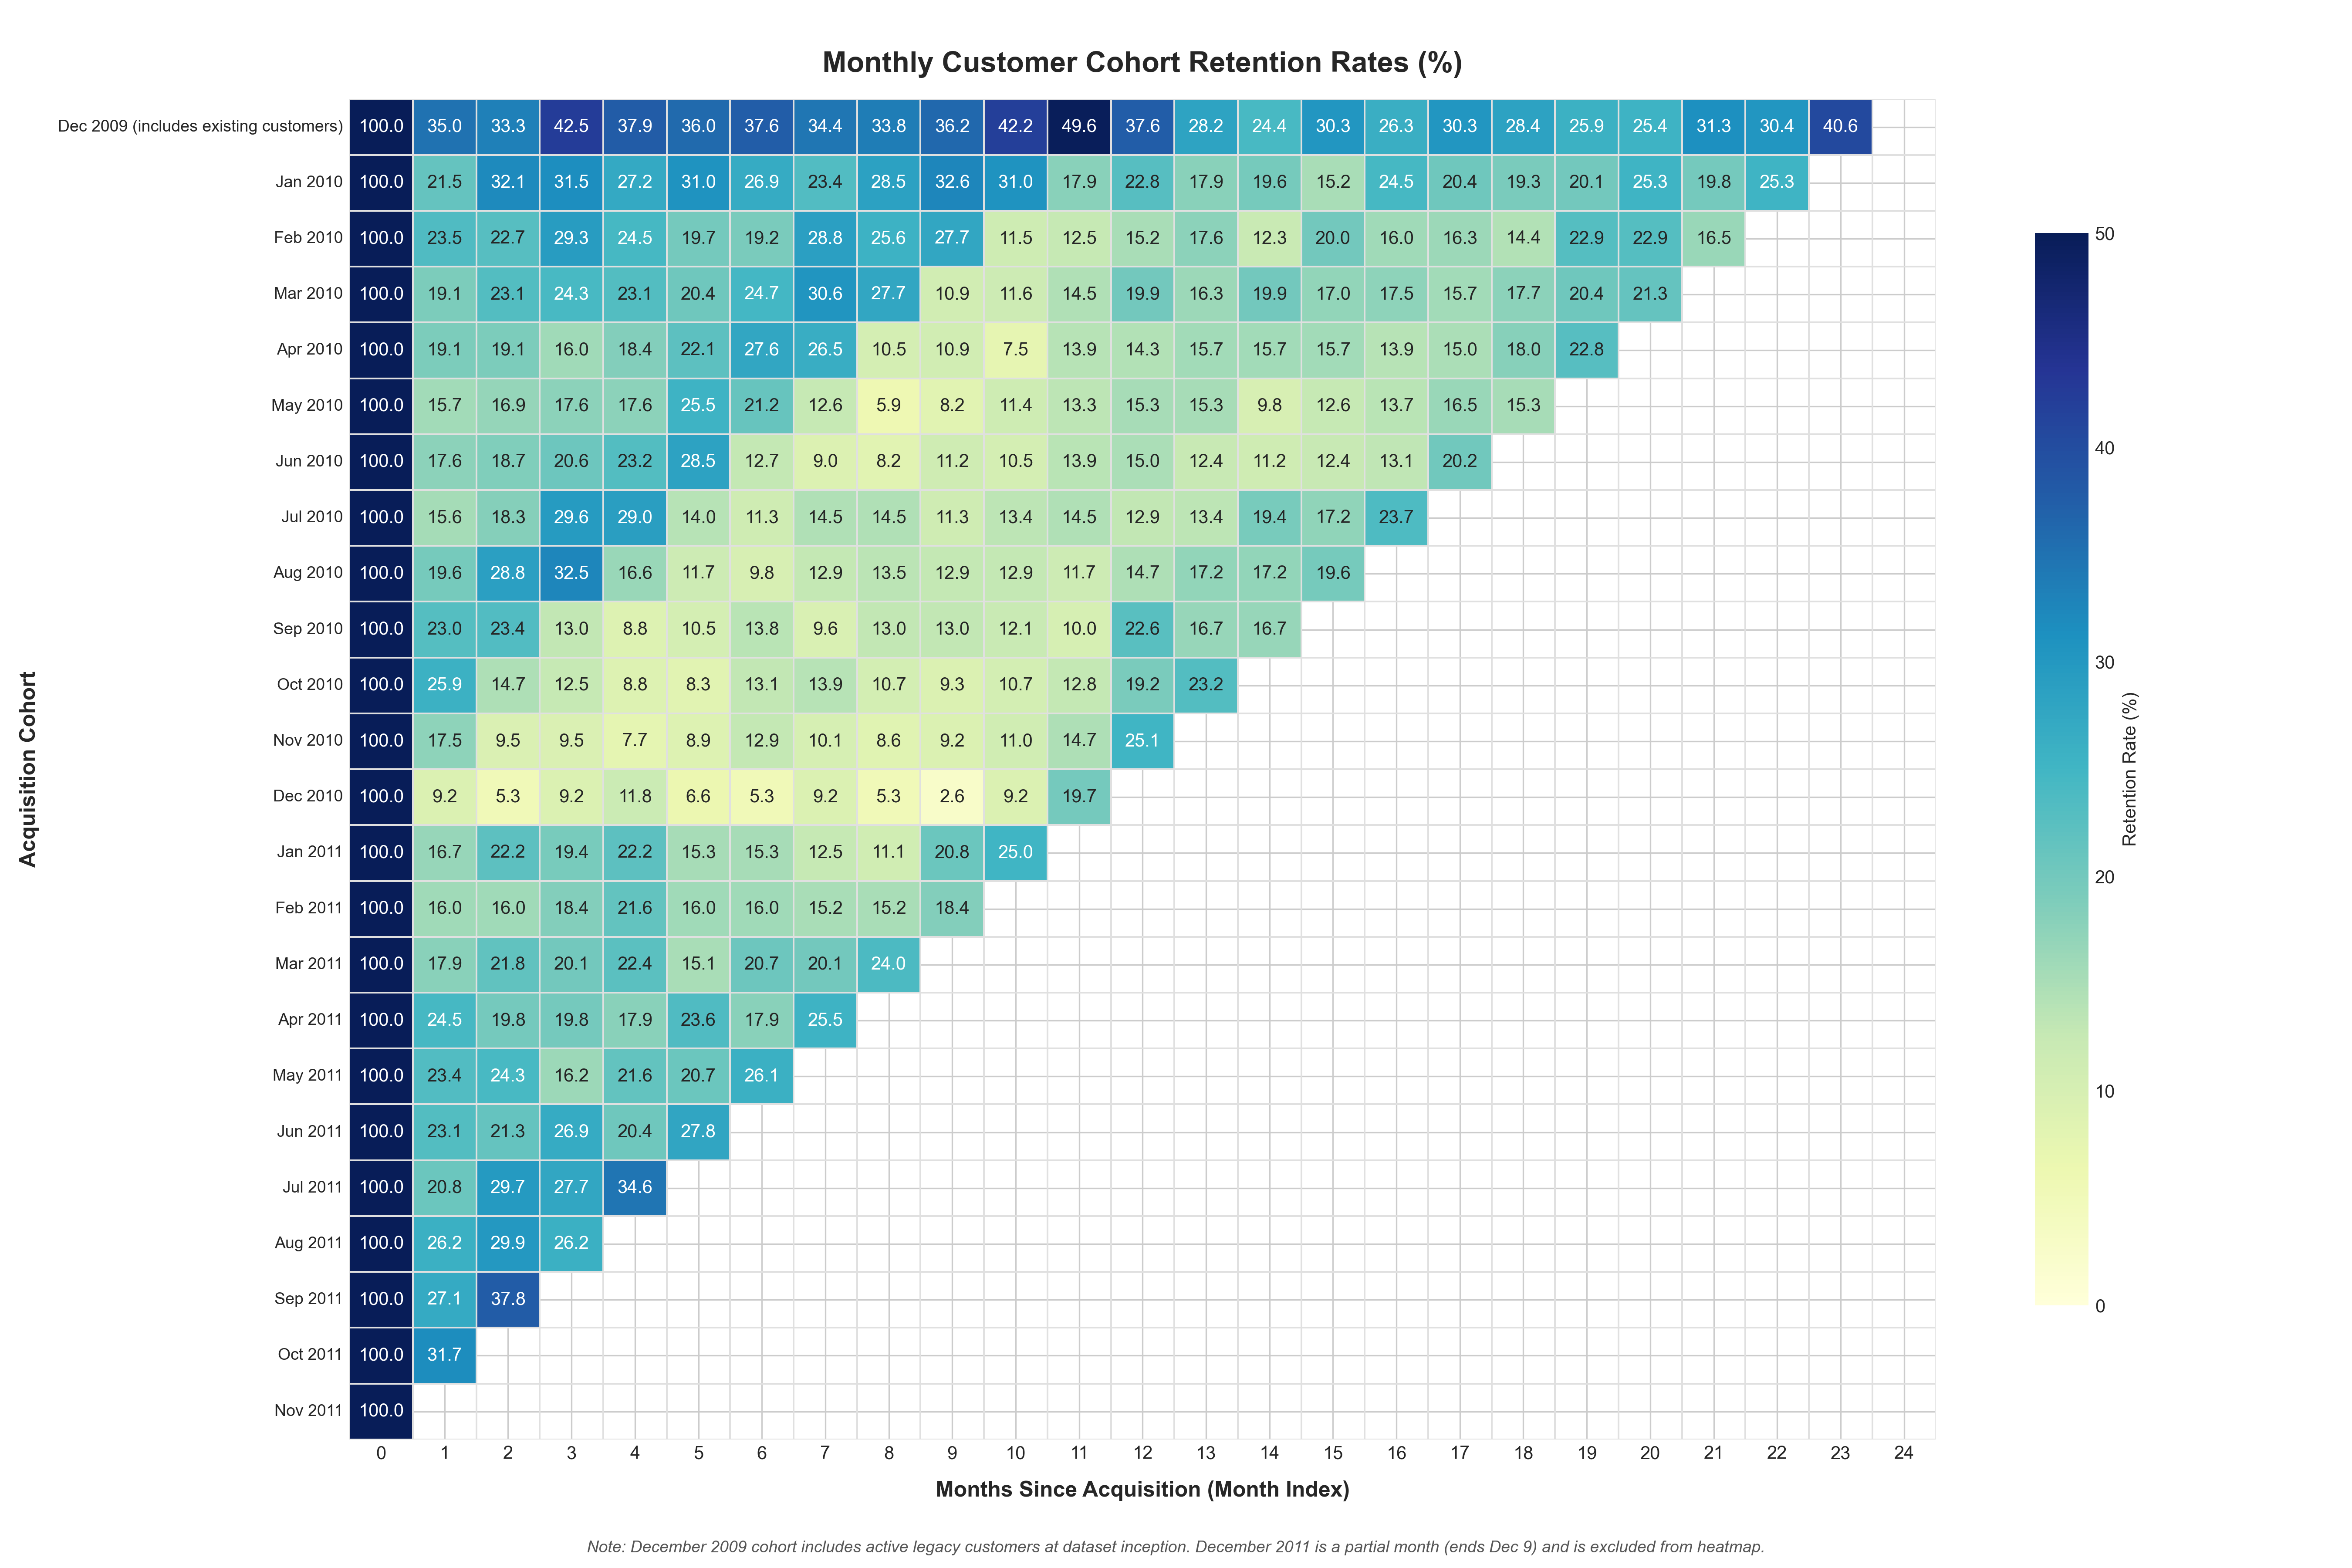

In [2]:
cohort_df = pd.read_csv(PROCESSED_DIR / 'cohort_retention.csv')

# Filter organic cohorts (excluding Dec 2009 and Dec 2011)
organic_cohorts = cohort_df[
    (~cohort_df['cohort_label'].str.contains('existing')) &
    (cohort_df['order_cohort_month'] != '2011-12-01')
]

benchmarks = []
for m in [1, 3, 6, 12]:
    subset = organic_cohorts[organic_cohorts['month_index'] == m]
    if len(subset) > 0:
        unweighted_avg = subset['retention_pct'].mean()
        cust_weighted_avg = subset['active_customers'].sum() / subset['cohort_size'].sum() * 100
        benchmarks.append({
            'Horizon': f'Month {m}',
            'Evaluated Cohorts': len(subset),
            'Unweighted Avg %': round(unweighted_avg, 2),
            'Customer-Weighted Avg %': round(cust_weighted_avg, 2),
            'Active / Cohort Customers': f"{subset['active_customers'].sum():,} / {subset['cohort_size'].sum():,}"
        })

display(pd.DataFrame(benchmarks))
display(Image(filename=str(FIGURES_DIR / 'cohort_retention_heatmap.png')))

## 2. RFM Customer Segmentation & Extreme Spend Concentration

Customers are classified into 7 mutually exclusive behavioral segments using snapshot date **2011-12-10**:
- **The 80/20 Rule:** Top 20% of customers (1,171 accounts) generate **77.17% of total revenue** (£13.18M).
- **Champions:** 1,390 accounts (23.75% of base) generate **68.46% of all revenue** (£11.69M) with 16.2 orders on average.

,segment,customers,pct_customers,revenue,pct_revenue,avg_recency,avg_frequency,avg_order_value
0,Champions,1390,23.75,11694374.86,68.46,20.1,16.2,415.21
1,Loyal,1189,20.31,2494669.85,14.60,76.7,5.6,366.22
2,Can't Lose Them,287,4.90,952698.87,5.58,338.3,8.6,359.51
3,Hibernating/Lost,1632,27.88,691967.71,4.05,454.1,1.3,327.26
4,At Risk,423,7.23,574985.10,3.37,374.3,3.4,412.38
5,New/Promising,509,8.70,442653.24,2.59,27.7,1.5,512.45
6,Need Attention,423,7.23,229779.10,1.35,107.4,1.4,391.56


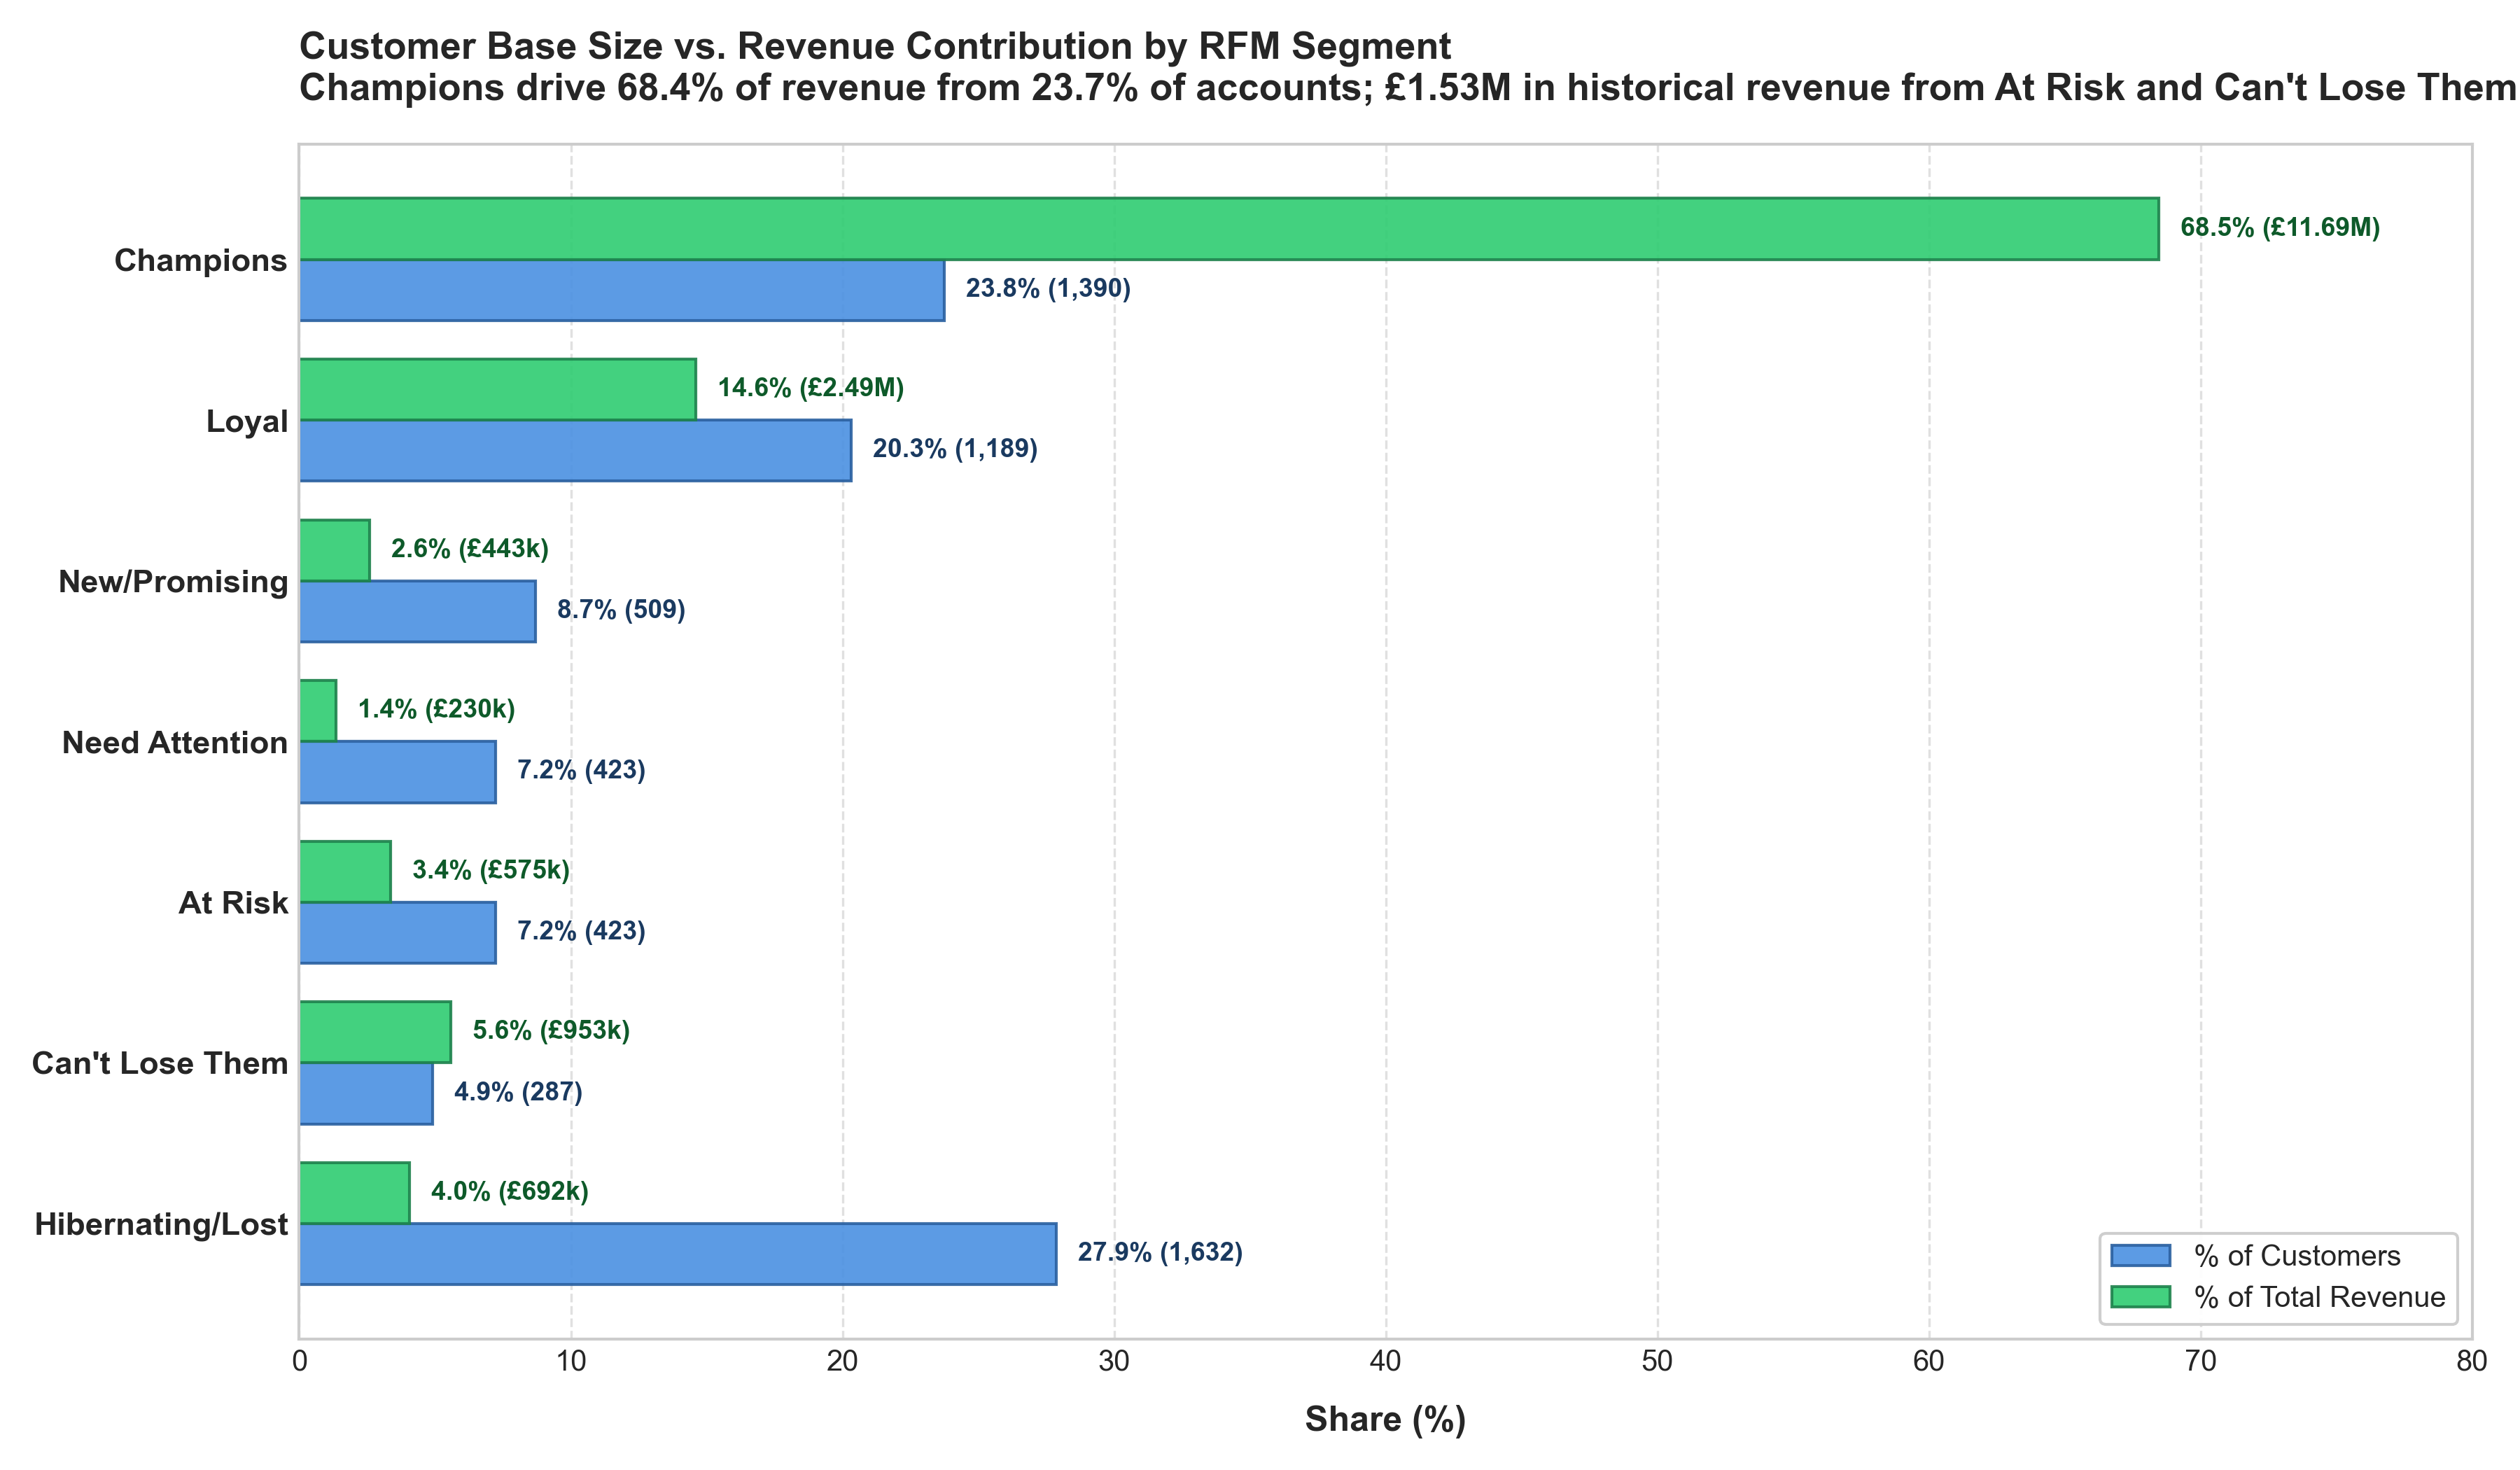

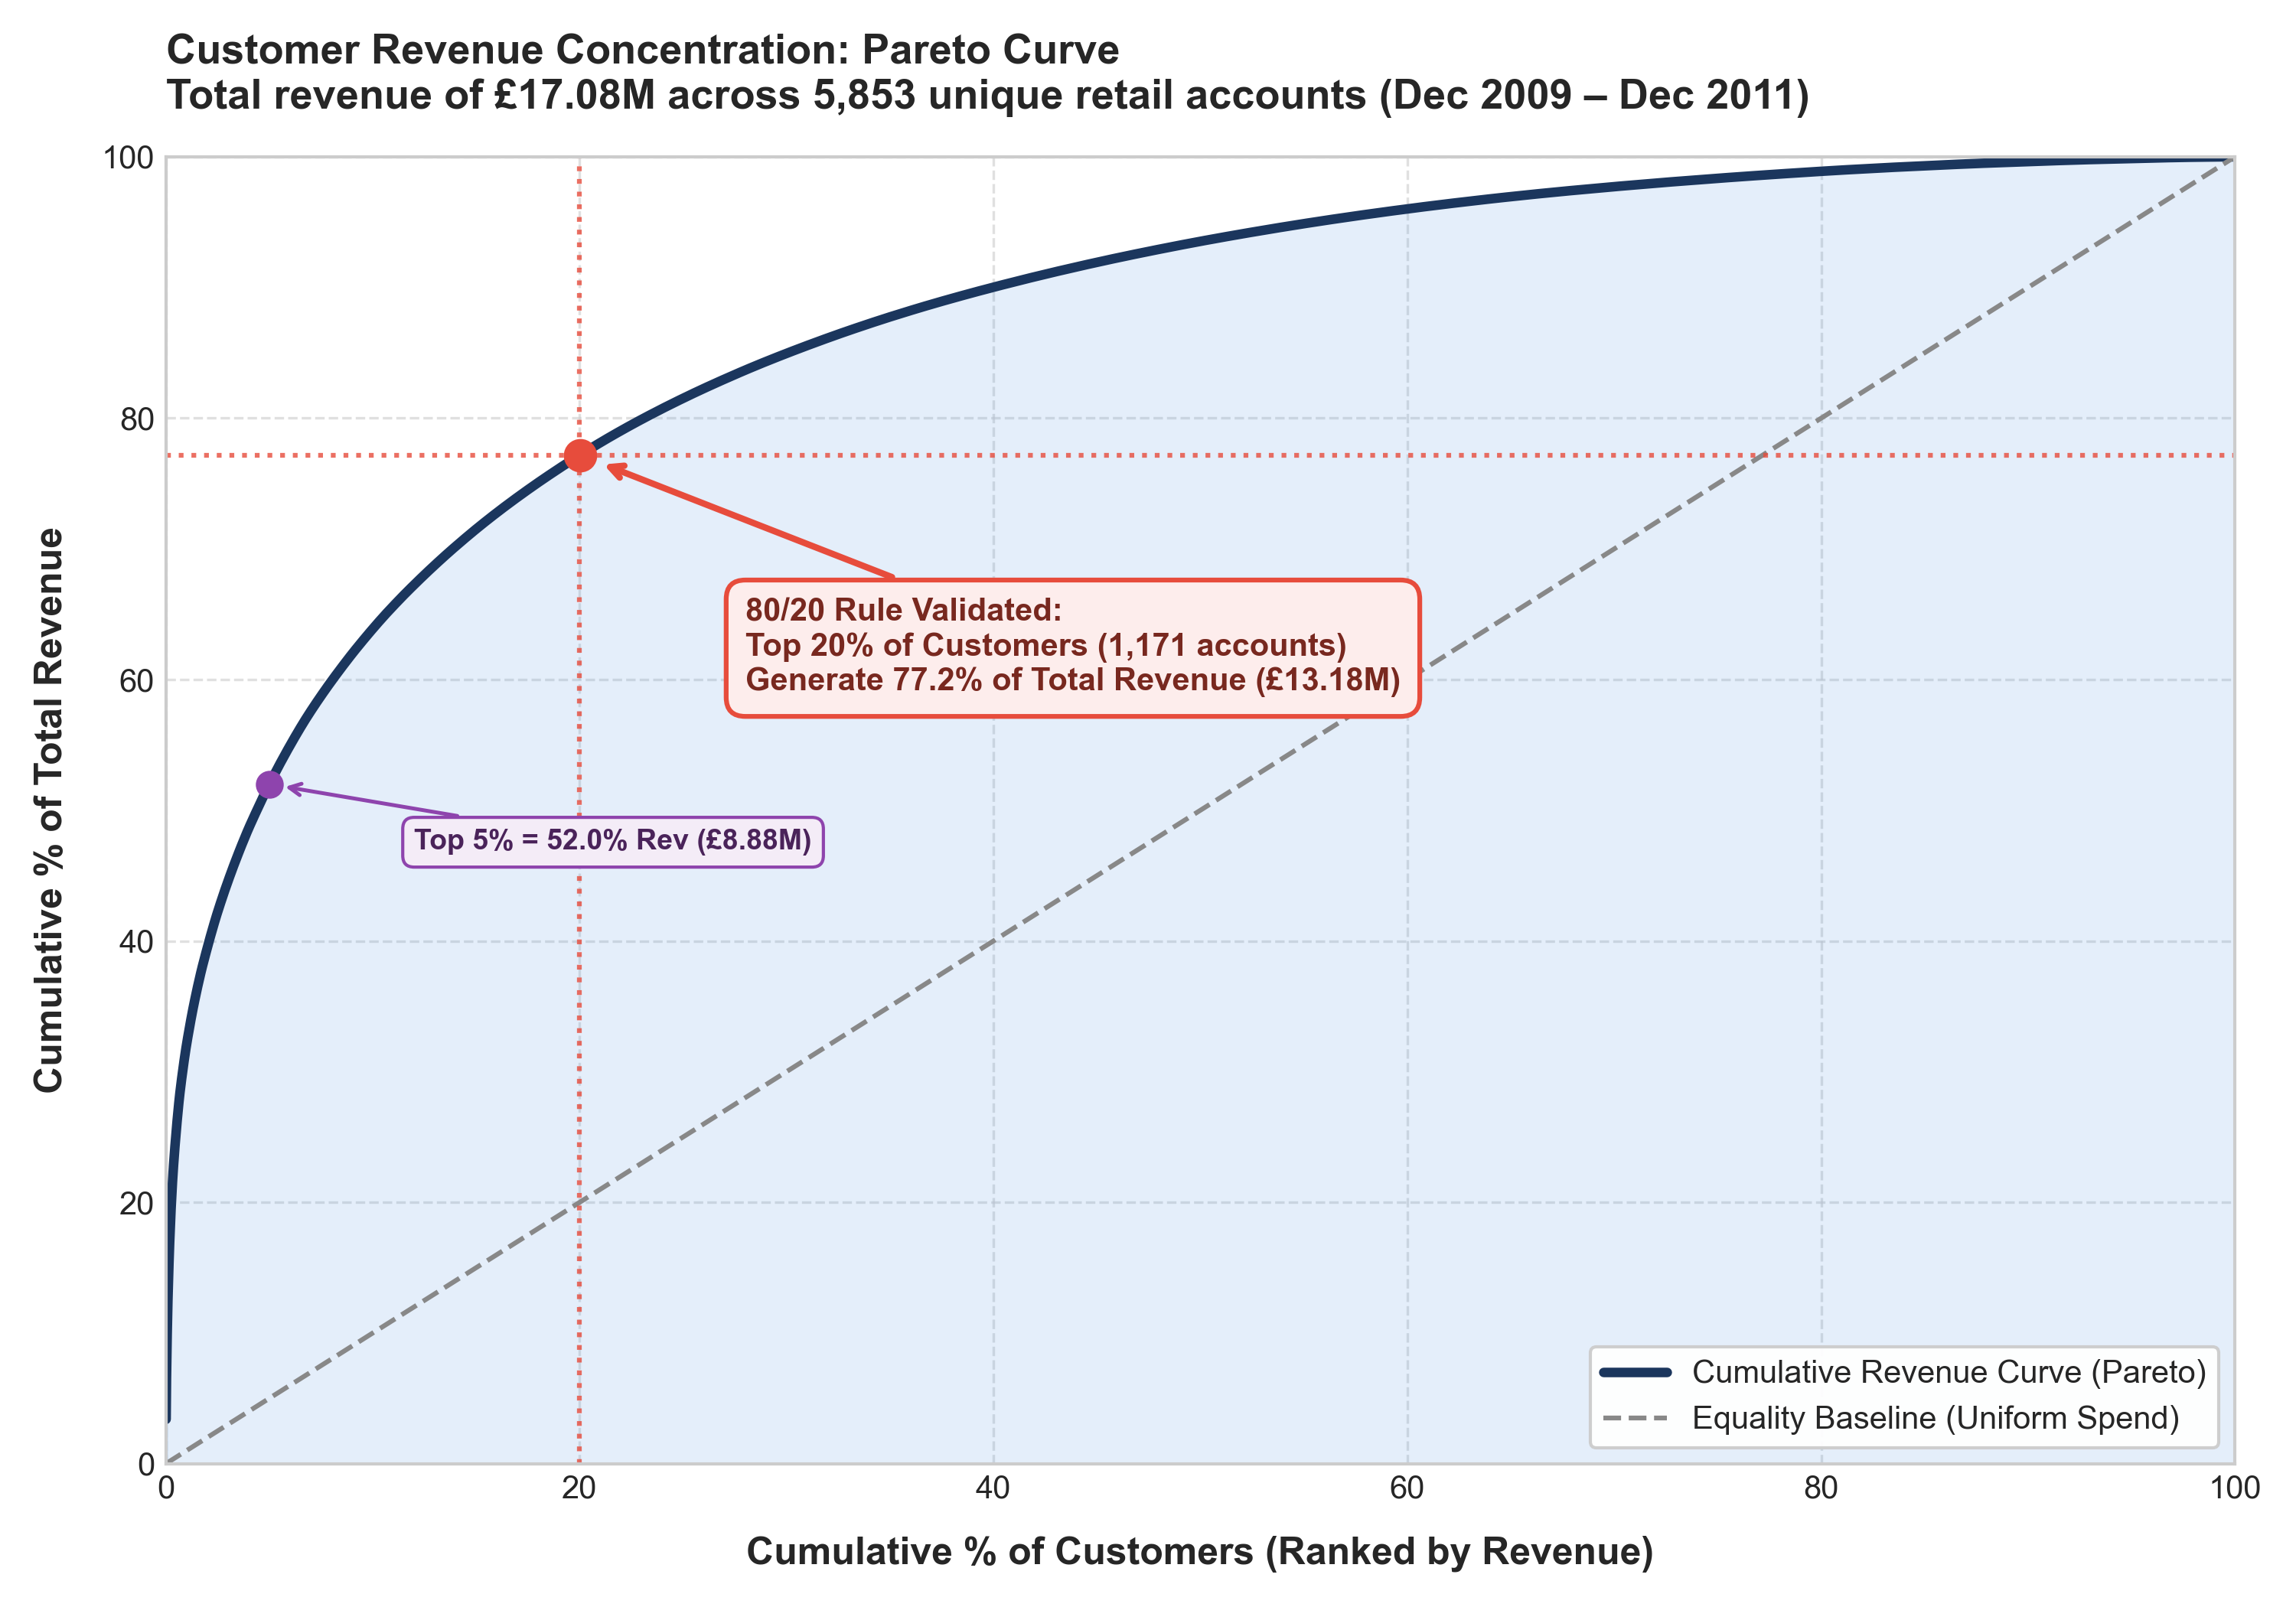

In [3]:
segment_df = pd.read_csv(PROCESSED_DIR / 'segment_summary.csv')
display(segment_df)
display(Image(filename=str(FIGURES_DIR / 'segment_size_vs_revenue.png')))
display(Image(filename=str(FIGURES_DIR / 'pareto_curve.png')))

## 3. Net Revenue-at-Risk Quantification (£769.1k Exposure)

Annualized Revenue-at-Risk is computed on **Net Revenue** post-cancellations:
> *"Gross Revenue-at-Risk was £886,993; net is £769,097 after removing cancelled orders (including a £77K same-day cancelled order that had ranked #2)."*

Across 710 accounts in `At Risk` and `Can't Lose Them` segments, net exposure is **£769,096.74** (7.87% of total net customer EAV).

,segment,customer_count,pct_of_customers,gross_revenue,returns_amount,net_revenue,gross_revenue_at_risk,revenue_at_risk,revenue_at_risk_pct
0,Can't Lose Them,287,4.90,952698.87,86550.20,866148.67,516432.19,480844.91,4.92
1,At Risk,423,7.23,574985.10,125186.75,449798.35,370560.95,288251.83,2.95
2,Total Revenue-at-Risk,710,12.13,1527683.97,211736.95,1315947.02,886993.14,769096.74,7.87


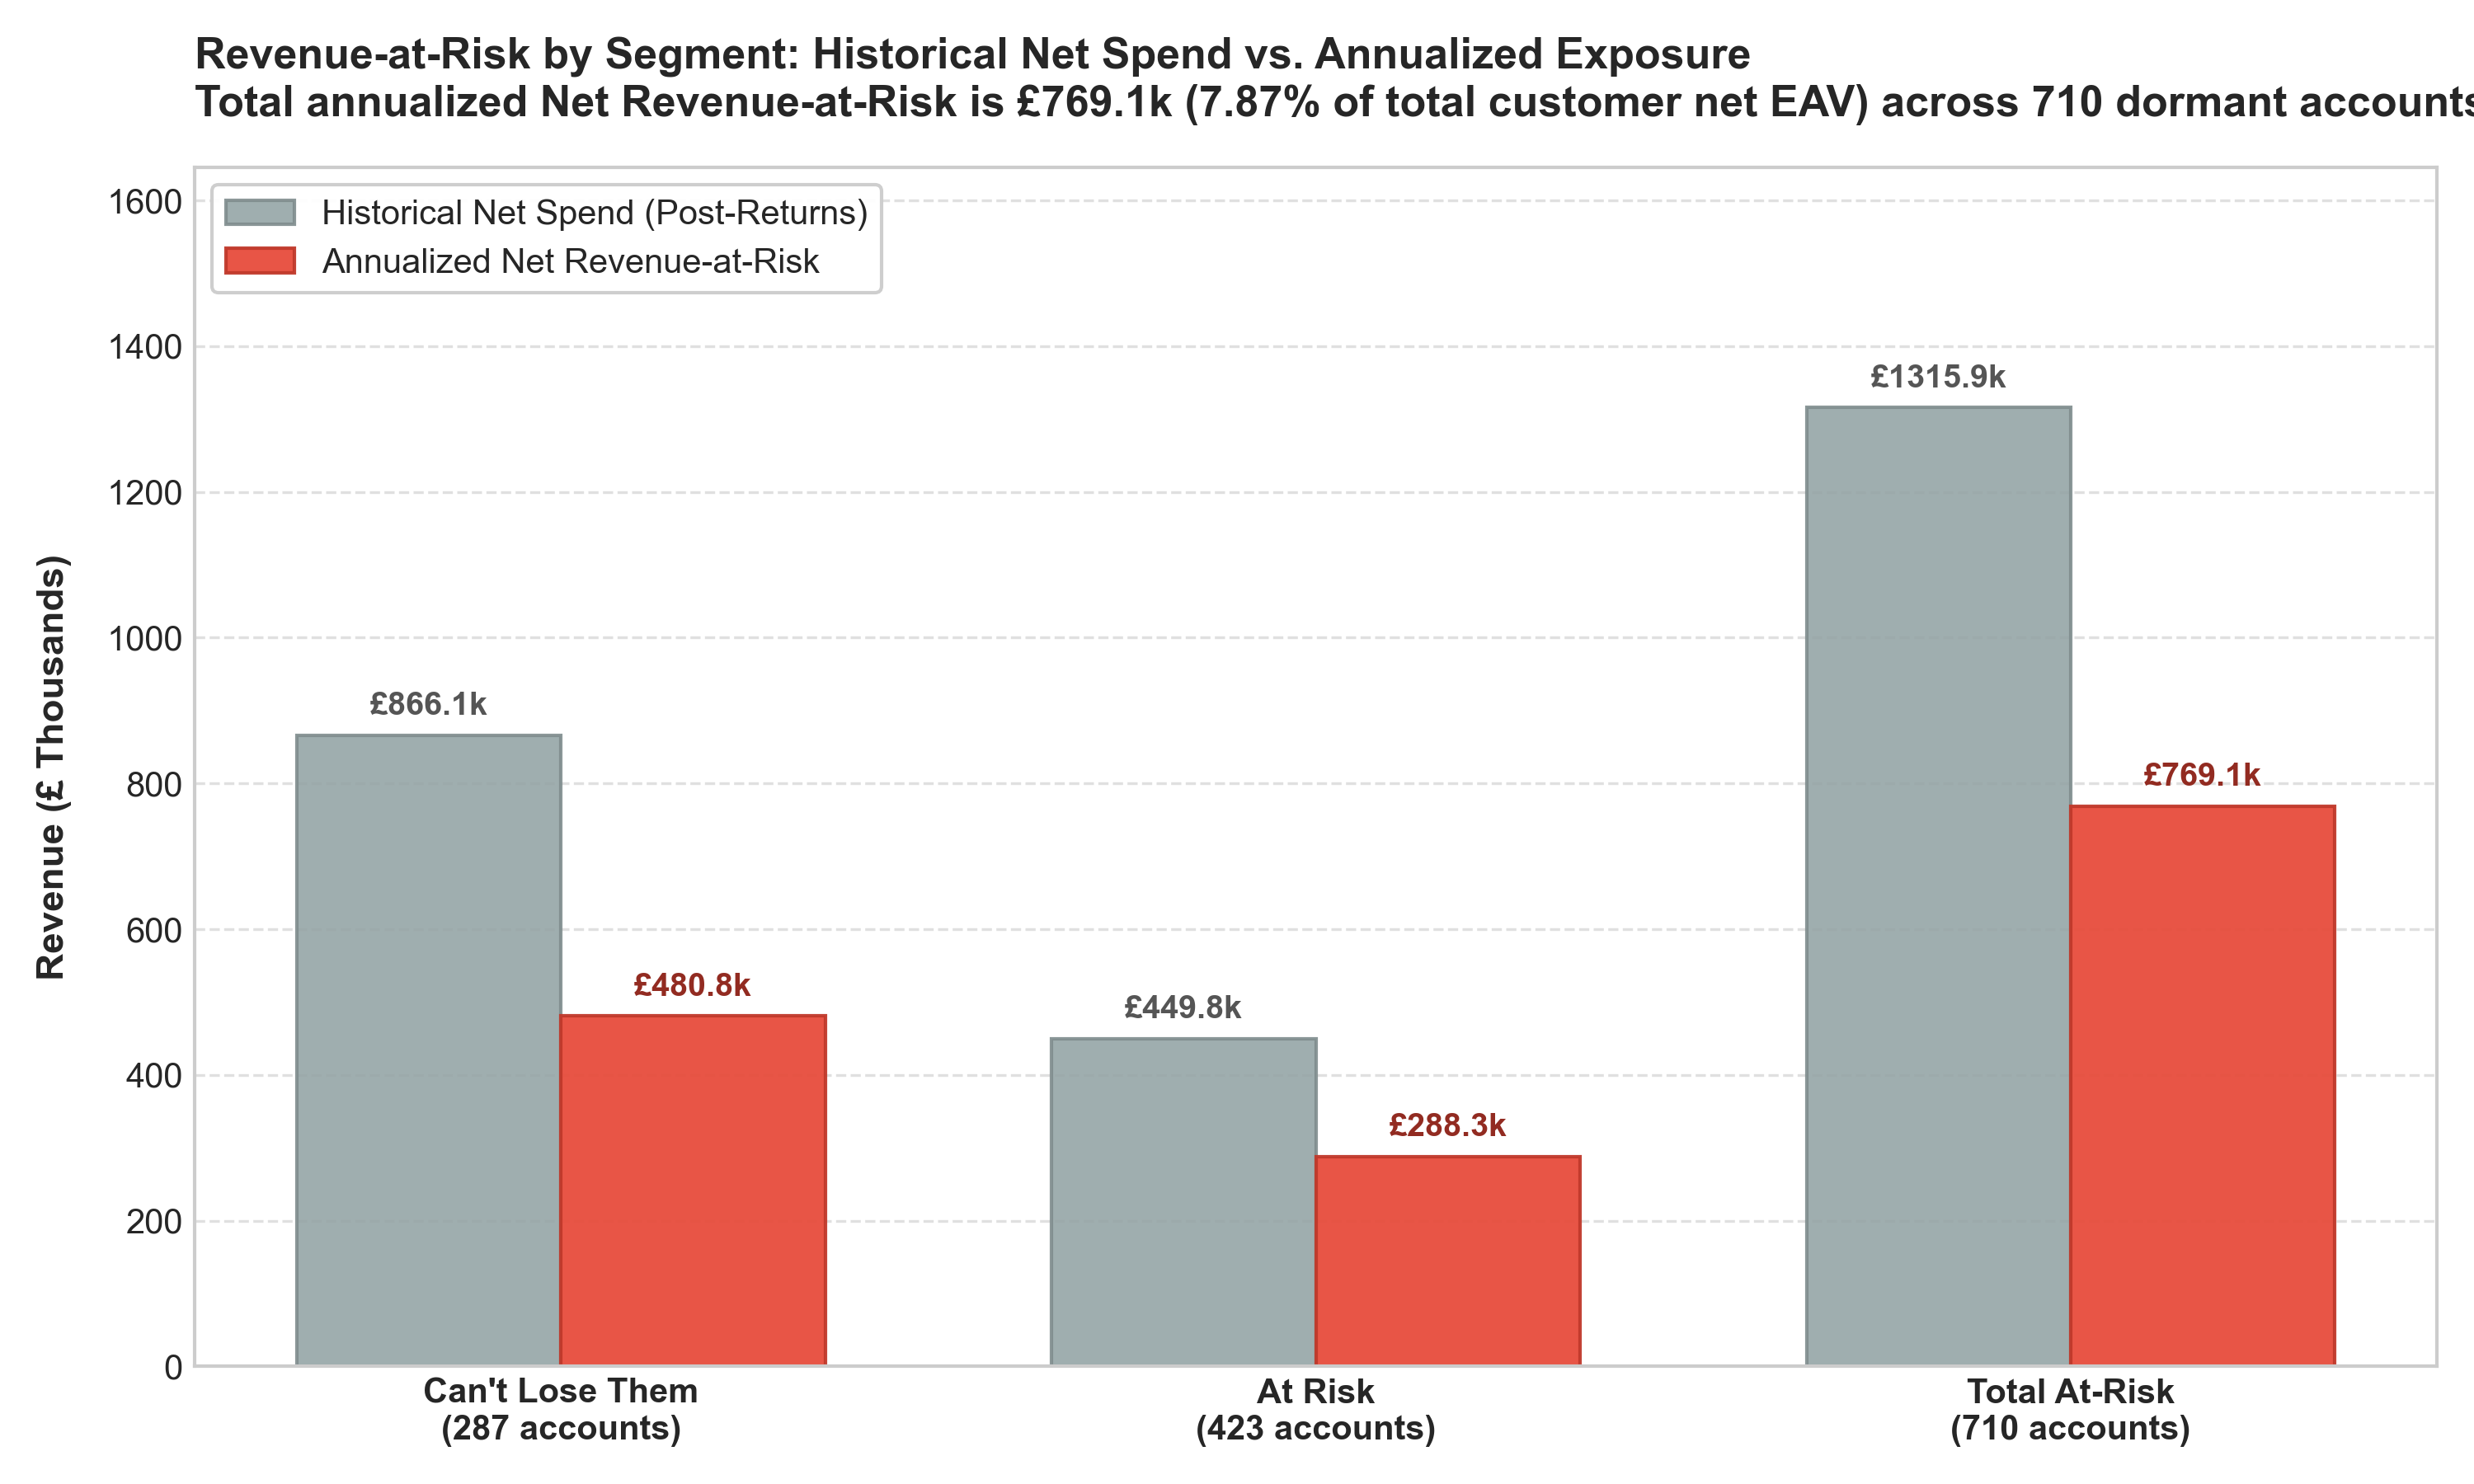

In [4]:
rar_df = pd.read_csv(PROCESSED_DIR / 'revenue_at_risk_summary.csv')
display(rar_df)
display(Image(filename=str(FIGURES_DIR / 'revenue_at_risk_by_segment.png')))

## 4. Win-Back Sensitivity Modeling & Top 10 Action List

Sensitivity analysis models annual revenue recovery across 5%, 10%, and 15% reclaim rates.
The prioritized action list ranks at-risk accounts by `net_expected_annual_value` descending.

,recovery_rate,scope,customers_targeted,revenue_at_risk_base,recovered_revenue,notes
0,5%,At Risk Only,423,288251.83,14412.59,"scenario assumptions, not forecasts"
1,5%,Both (Total At-Risk),710,769096.74,38454.84,"scenario assumptions, not forecasts"
2,5%,Can't Lose Them Only,287,480844.91,24042.25,"scenario assumptions, not forecasts"
3,10%,At Risk Only,423,288251.83,28825.18,"scenario assumptions, not forecasts"
4,10%,Both (Total At-Risk),710,769096.74,76909.67,"scenario assumptions, not forecasts"
5,10%,Can't Lose Them Only,287,480844.91,48084.49,"scenario assumptions, not forecasts"
6,15%,At Risk Only,423,288251.83,43237.77,"scenario assumptions, not forecasts"
7,15%,Both (Total At-Risk),710,769096.74,115364.51,"scenario assumptions, not forecasts"
8,15%,Can't Lose Them Only,287,480844.91,72126.74,"scenario assumptions, not forecasts"


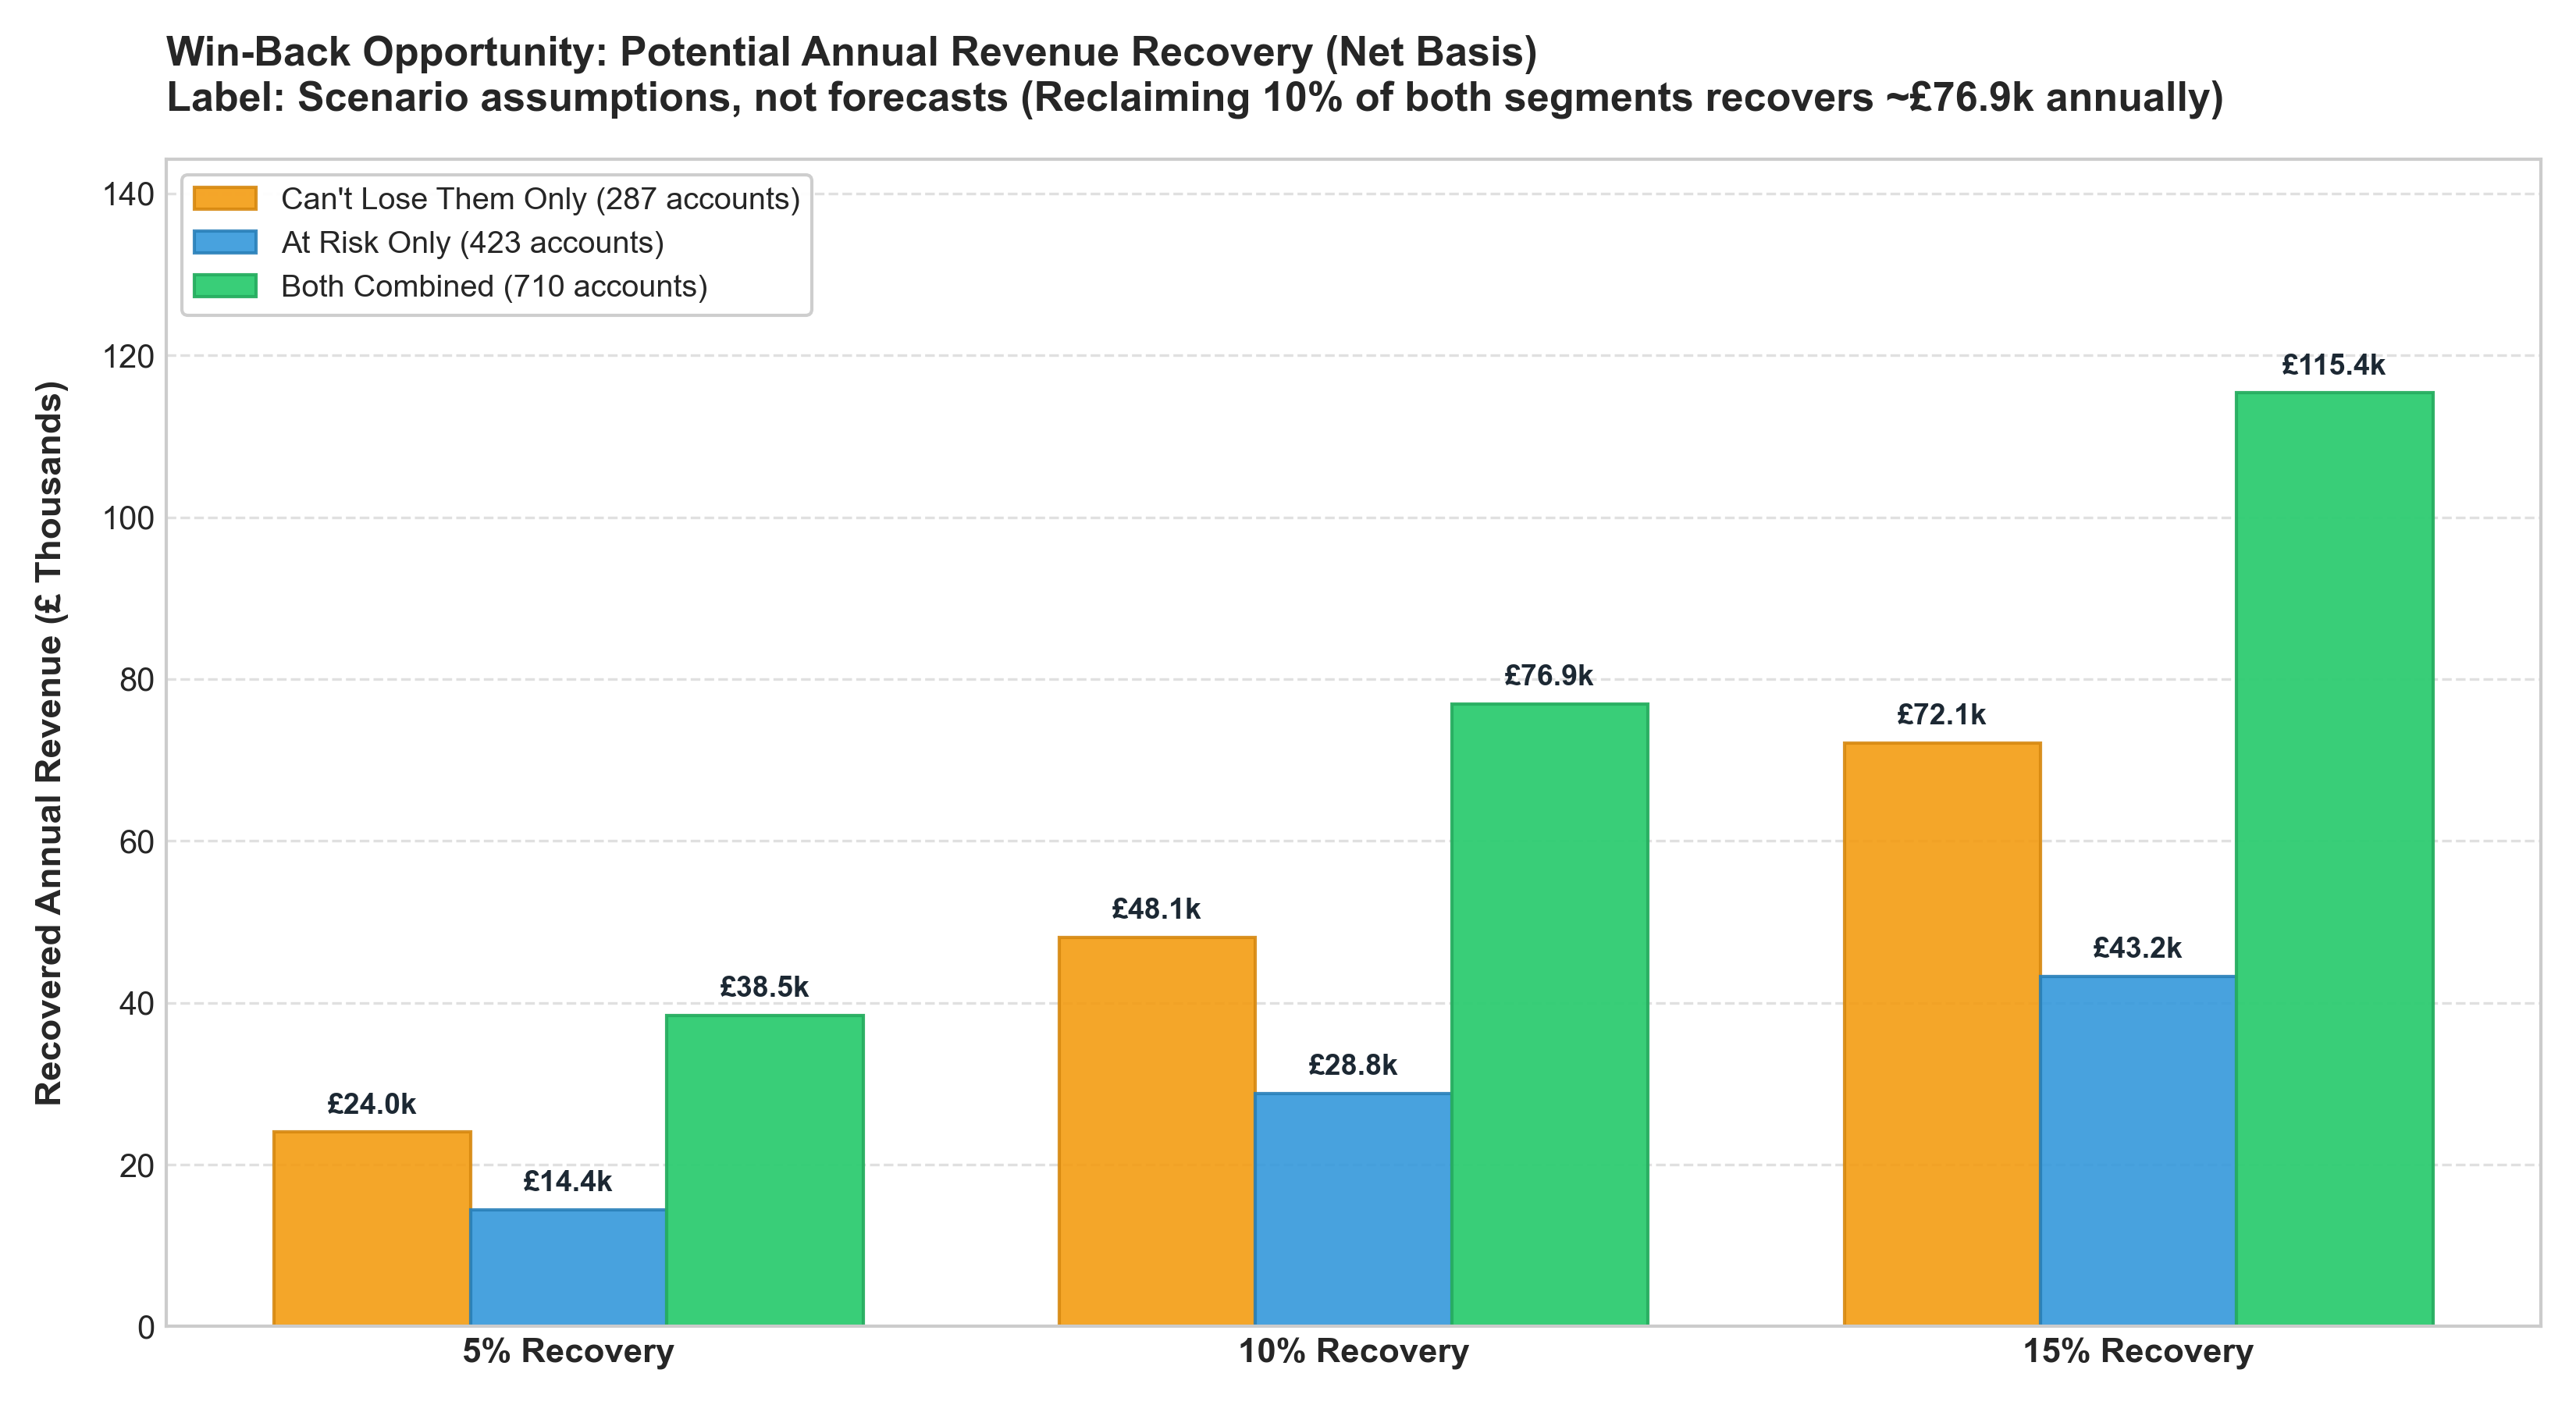

Top 50 action list total net revenue-at-risk: £289,143.66


,customer_id,country,segment,recency_days,order_count,total_revenue,returns_amount,net_revenue,return_pct,returns_flag,gross_expected_annual_value,net_expected_annual_value,suggested_action
0,16754,United Kingdom,Can't Lose Them,373,29,65500.07,10941.89,54558.18,16.71,False,37239.14,31018.28,personal call + loyalty offer
1,13093,United Kingdom,Can't Lose Them,276,55,54144.25,869.92,53274.33,1.61,False,26851.43,26420.01,personal call + loyalty offer
2,17850,United Kingdom,Can't Lose Them,373,155,51208.87,801.10,50407.77,1.56,False,25430.26,25032.43,personal call + loyalty offer
3,15749,United Kingdom,At Risk,236,3,44534.30,22998.40,21535.90,51.64,True,44534.30,21535.90,win-back email with a discount
4,13902,Denmark,Can't Lose Them,633,5,34023.26,3684.00,30339.26,10.83,False,17128.95,15274.25,personal call + loyalty offer
5,12482,Sweden,Can't Lose Them,577,27,21941.72,1797.87,20143.85,8.19,False,12245.76,11242.36,personal call + loyalty offer
6,15808,United Kingdom,Can't Lose Them,307,21,17180.25,141.30,17038.95,0.82,False,8485.51,8415.72,personal call + loyalty offer
7,13564,United Kingdom,Can't Lose Them,355,36,15880.22,1462.83,14417.39,9.21,False,7854.04,7130.55,personal call + loyalty offer
8,18087,United Kingdom,Can't Lose Them,291,16,13908.72,349.90,13558.82,2.52,False,6869.67,6696.85,personal call + loyalty offer
9,13952,United Kingdom,Can't Lose Them,218,14,12823.52,32.63,12790.89,0.25,False,6464.90,6448.45,personal call + loyalty offer


In [5]:
scenarios_df = pd.read_csv(PROCESSED_DIR / 'win_back_scenarios.csv')
display(scenarios_df)
display(Image(filename=str(FIGURES_DIR / 'win_back_scenarios.png')))

# Display Top 10 Action List accounts
action_df = pd.read_csv(PROCESSED_DIR / 'action_list.csv')
print(f'Top 50 action list total net revenue-at-risk: £{action_df["net_expected_annual_value"].sum():,.2f}')
display(action_df[['customer_id', 'country', 'segment', 'recency_days', 'order_count', 
                   'total_revenue', 'returns_amount', 'net_revenue', 'return_pct', 
                   'returns_flag', 'gross_expected_annual_value', 'net_expected_annual_value', 'suggested_action']].head(10))

## 5. Strategic Recommendations & Key Next Steps

1. **Deploy High-Touch Account Management for `Can't Lose Them`:** 41 accounts in the top 50 warrant direct phone calls and personalized contract terms.
2. **Automate Win-Back Email Sequences for `At Risk`:** Launch automated margin-protected discount campaigns for dormant repeat buyers.
3. **Incorporate Returns Visibility:** Accounts with `returns_flag = True` (e.g., account `15749`) require return root-cause analysis before aggressive discount extensions.